# Seoul Link Speed EDA Report

강수량, 경사도, 도로등급, 첨두시간대가 링크 평균속도에 미치는 영향을 탐색합니다.

이 노트북은 예전의 `10_analyze_speed_feature_effects.py` + `11_plot_eda_tables.py` + `12_plot_eda_charts.py` 세 스크립트를 하나로 합친 것입니다.
집계 테이블은 셀 출력으로 바로 확인하고, 보고서용 차트만 `docs/figures/eda/`에 저장합니다.

**입력**: `data/processed/seoul_link_speed_dem_weather_merged.csv` (속도 + 링크속성 + DEM 경사도 + 레이더 강수 결합 테이블)

**주의**: 이 결과는 인과관계 검증이 아니라 탐색적 분석입니다. 최종 해석에서는 시간대, 도로등급, 제한속도, 링크별 특성을 함께 통제해야 합니다.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Jupyter 실행 위치가 notebooks/ 폴더라고 가정합니다 (jupyter lab/notebook 기본 동작).
PROJECT_ROOT = Path.cwd().parent
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
DOCS_FIGURES_DIR = PROJECT_ROOT / "docs" / "figures" / "eda"
DOCS_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

INPUT_PATH = PROCESSED_DATA_DIR / "seoul_link_speed_dem_weather_merged.csv"

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

COLORS = {
    "no_rain": "#4C78A8",
    "rain": "#E45756",
    "bar": "#59A14F",
    "line": "#2F4B7C",
}

In [2]:
usecols = [
    "평균속도",
    "precip_mm",
    "slope_pct",
    "abs_slope_pct",
    "elev_mean_m",
    "elev_delta_m",
    "ROAD_RANK",
    "MAX_SPD",
    "LENGTH",
    "시간코드",
    "첨두시구분(T1/T2/T3:오전/낮/오후)",
]
df = pd.read_csv(INPUT_PATH, usecols=usecols, encoding="utf-8-sig")

for column in ["평균속도", "precip_mm", "slope_pct", "abs_slope_pct", "elev_mean_m", "elev_delta_m"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df = df.dropna(subset=["평균속도", "precip_mm", "abs_slope_pct"])

df["rain_flag"] = np.where(df["precip_mm"] > 0, "rain", "no_rain")
df["rain_bin"] = pd.cut(
    df["precip_mm"],
    bins=[-0.001, 0, 1, 5, 10, np.inf],
    labels=["0mm", "0-1mm", "1-5mm", "5-10mm", "10mm+"],
    include_lowest=True,
)
df["abs_slope_bin"] = pd.cut(
    df["abs_slope_pct"],
    bins=[-0.001, 1, 3, 5, 10, np.inf],
    labels=["0-1%", "1-3%", "3-5%", "5-10%", "10%+"],
    include_lowest=True,
)
df["slope_direction"] = pd.cut(
    df["slope_pct"],
    bins=[-np.inf, -1, 1, np.inf],
    labels=["downhill", "flat", "uphill"],
)
df["slope_risk"] = np.where(df["abs_slope_pct"] >= 5, "steep", "not_steep")
df["rain_slope_group"] = df["rain_flag"] + " + " + df["slope_risk"]

print("행 수:", len(df))
df.head()

행 수: 2619332


,시간코드,첨두시구분(T1/T2/T3:오전/낮/오후),ROAD_RANK,MAX_SPD,LENGTH,평균속도,elev_mean_m,elev_delta_m,slope_pct,abs_slope_pct,precip_mm,rain_flag,rain_bin,abs_slope_bin,slope_direction,slope_risk,rain_slope_group
0,2,N,103,50,45.892773,14.22,29.623407,0.0,0.0,0.0,0.000000,no_rain,0mm,0-1%,flat,not_steep,no_rain + not_steep
1,3,N,103,50,45.892773,15.47,29.623407,0.0,0.0,0.0,0.000000,no_rain,0mm,0-1%,flat,not_steep,no_rain + not_steep
2,4,N,103,50,45.892773,15.87,29.623407,0.0,0.0,0.0,0.000000,no_rain,0mm,0-1%,flat,not_steep,no_rain + not_steep
3,5,N,103,50,45.892773,17.00,29.623407,0.0,0.0,0.0,0.000000,no_rain,0mm,0-1%,flat,not_steep,no_rain + not_steep
4,6,N,103,50,45.892773,29.28,29.623407,0.0,0.0,0.0,32.830002,rain,10mm+,0-1%,flat,not_steep,rain + not_steep


In [3]:
def summarize(grouped) -> pd.DataFrame:
    return (
        grouped["평균속도"]
        .agg(row_count="count", mean_speed="mean", median_speed="median", std_speed="std")
        .reset_index()
        .assign(
            mean_speed=lambda d: d["mean_speed"].round(2),
            median_speed=lambda d: d["median_speed"].round(2),
            std_speed=lambda d: d["std_speed"].round(2),
        )
    )


def add_labels(ax, fmt="{:.1f}", dy=0.25):
    for patch in ax.patches:
        height = patch.get_height()
        if pd.isna(height):
            continue
        ax.text(
            patch.get_x() + patch.get_width() / 2,
            height + dy,
            fmt.format(height),
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold",
        )


def finish(fig, ax, out_name: str, ylim_pad=0.16):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", color="#E5E7EB", linewidth=0.8)
    ax.set_axisbelow(True)
    top = ax.get_ylim()[1]
    ax.set_ylim(0, top * (1 + ylim_pad))
    fig.tight_layout()
    fig.savefig(DOCS_FIGURES_DIR / out_name, dpi=220, bbox_inches="tight")
    plt.show()
    print("저장:", DOCS_FIGURES_DIR / out_name)

## 1. 강수 여부별 평균속도

In [4]:
speed_by_rain_flag = summarize(df.groupby("rain_flag", observed=True))
speed_by_rain_flag

,rain_flag,row_count,mean_speed,median_speed,std_speed
0,no_rain,2068958,26.05,23.57,12.39
1,rain,550374,25.59,23.37,11.71


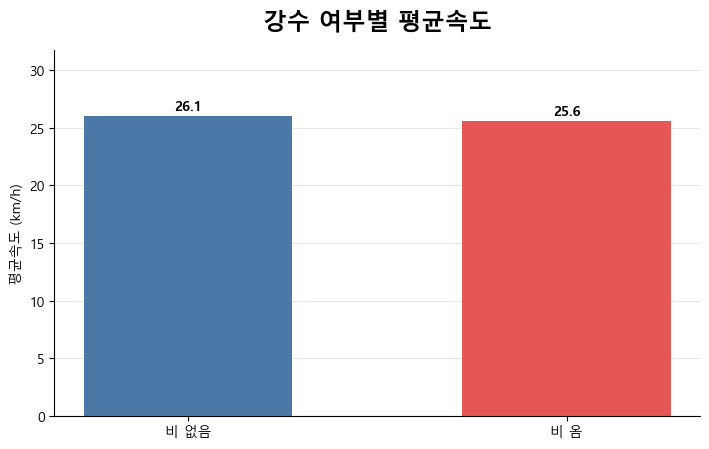

저장: C:\Users\ejjun\Desktop\seoul-eco-routing\docs\figures\eda\01_rain_flag_speed.png


In [5]:
order = ["no_rain", "rain"]
plot_df = speed_by_rain_flag.set_index("rain_flag").loc[order].reset_index()

fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.bar(["비 없음", "비 옴"], plot_df["mean_speed"], color=[COLORS["no_rain"], COLORS["rain"]], width=0.55)
ax.set_title("강수 여부별 평균속도", fontsize=17, fontweight="bold", pad=16)
ax.set_ylabel("평균속도 (km/h)")
add_labels(ax)
finish(fig, ax, "01_rain_flag_speed.png")

## 2. 강수량 구간별 평균속도

In [6]:
speed_by_rain_bin = summarize(df.groupby("rain_bin", observed=True))
speed_by_rain_bin

,rain_bin,row_count,mean_speed,median_speed,std_speed
0,0mm,2068958,26.05,23.57,12.39
1,0-1mm,16987,26.49,24.08,12.16
2,1-5mm,36051,27.06,24.35,12.77
3,5-10mm,59780,26.46,24.01,12.30
4,10mm+,437556,25.31,23.17,11.50


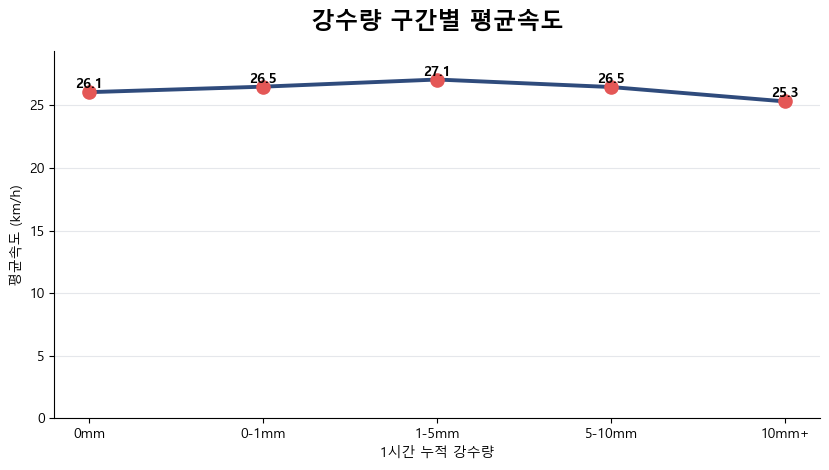

저장: C:\Users\ejjun\Desktop\seoul-eco-routing\docs\figures\eda\02_rain_intensity_speed.png


In [7]:
labels = speed_by_rain_bin["rain_bin"].tolist()

fig, ax = plt.subplots(figsize=(8.4, 4.8))
ax.plot(labels, speed_by_rain_bin["mean_speed"], color=COLORS["line"], marker="o", linewidth=2.8)
ax.scatter(labels, speed_by_rain_bin["mean_speed"], s=90, color=COLORS["rain"], zorder=3)
for x, y in zip(labels, speed_by_rain_bin["mean_speed"]):
    ax.text(x, y + 0.08, f"{y:.1f}", ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_title("강수량 구간별 평균속도", fontsize=17, fontweight="bold", pad=16)
ax.set_xlabel("1시간 누적 강수량")
ax.set_ylabel("평균속도 (km/h)")
finish(fig, ax, "02_rain_intensity_speed.png", ylim_pad=0.08)

## 3. 경사도 구간별 평균속도

In [8]:
speed_by_abs_slope_bin = summarize(df.groupby("abs_slope_bin", observed=True))
speed_by_abs_slope_bin

,abs_slope_bin,row_count,mean_speed,median_speed,std_speed
0,0-1%,1421634,25.66,23.17,12.36
1,1-3%,610560,25.88,23.53,12.10
2,3-5%,241562,26.22,23.91,11.91
3,5-10%,220864,26.34,24.24,11.55
4,10%+,124712,28.42,25.47,13.28


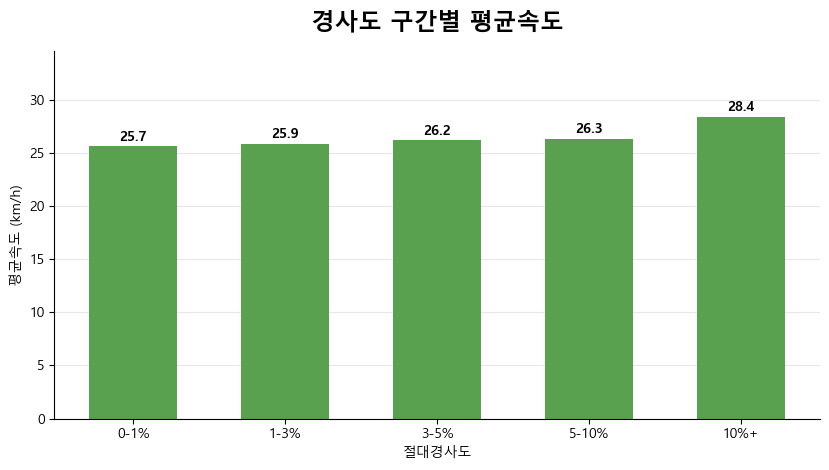

저장: C:\Users\ejjun\Desktop\seoul-eco-routing\docs\figures\eda\03_slope_bin_speed.png


In [9]:
fig, ax = plt.subplots(figsize=(8.4, 4.8))
ax.bar(speed_by_abs_slope_bin["abs_slope_bin"], speed_by_abs_slope_bin["mean_speed"], color=COLORS["bar"], width=0.58)
ax.set_title("경사도 구간별 평균속도", fontsize=17, fontweight="bold", pad=16)
ax.set_xlabel("절대경사도")
ax.set_ylabel("평균속도 (km/h)")
add_labels(ax)
finish(fig, ax, "03_slope_bin_speed.png")

## 4. 강수 x 급경사 조합별 평균속도

In [10]:
speed_by_rain_slope_group = summarize(df.groupby("rain_slope_group", observed=True))
speed_by_rain_slope_group

,rain_slope_group,row_count,mean_speed,median_speed,std_speed
0,no_rain + not_steep,1796611,25.88,23.39,12.40
1,no_rain + steep,272347,27.14,24.75,12.28
2,rain + not_steep,477145,25.39,23.17,11.64
3,rain + steep,73229,26.88,24.64,12.07


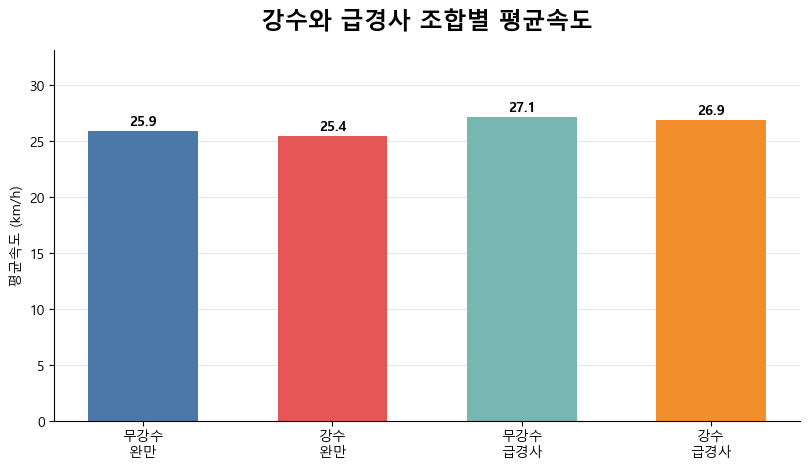

저장: C:\Users\ejjun\Desktop\seoul-eco-routing\docs\figures\eda\04_rain_slope_combo_speed.png


In [11]:
order = ["no_rain + not_steep", "rain + not_steep", "no_rain + steep", "rain + steep"]
labels = ["무강수\n완만", "강수\n완만", "무강수\n급경사", "강수\n급경사"]
plot_df = speed_by_rain_slope_group.set_index("rain_slope_group").loc[order].reset_index()

fig, ax = plt.subplots(figsize=(8.2, 4.8))
ax.bar(labels, plot_df["mean_speed"], color=["#4C78A8", "#E45756", "#76B7B2", "#F28E2B"], width=0.58)
ax.set_title("강수와 급경사 조합별 평균속도", fontsize=17, fontweight="bold", pad=16)
ax.set_ylabel("평균속도 (km/h)")
add_labels(ax)
finish(fig, ax, "04_rain_slope_combo_speed.png")

## 5. 첨두시간대별 강수 영향

In [12]:
speed_by_peak_rain = summarize(df.groupby(["첨두시구분(T1/T2/T3:오전/낮/오후)", "rain_flag"], observed=True))
speed_by_peak_rain

,첨두시구분(T1/T2/T3:오전/낮/오후),rain_flag,row_count,mean_speed,median_speed,std_speed
0,N,no_rain,1538355,26.82,24.23,12.67
1,N,rain,420657,26.55,24.24,12.00
2,T1,no_rain,175675,25.34,23.22,11.38
3,T1,rain,44445,23.01,21.50,9.92
4,T2,no_rain,167730,24.21,21.76,11.36
5,T2,rain,52374,23.30,21.00,10.38
6,T3,no_rain,187198,22.04,19.98,10.82
7,T3,rain,32898,20.37,18.68,9.65


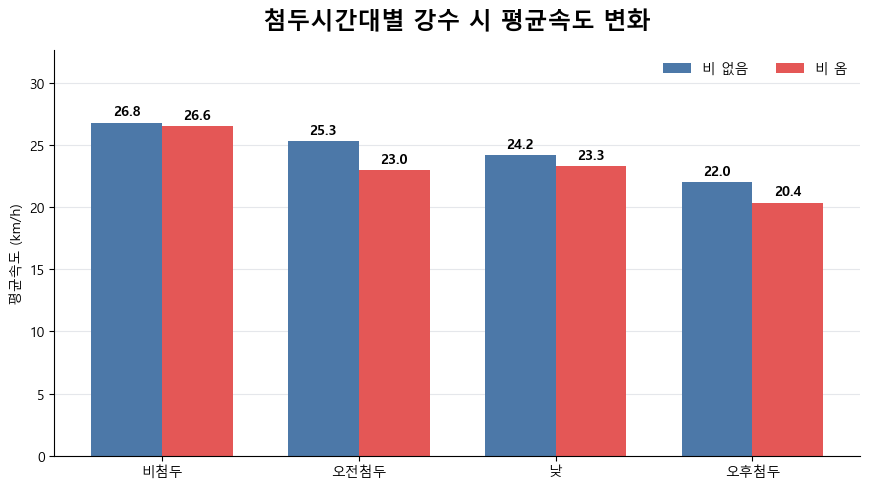

저장: C:\Users\ejjun\Desktop\seoul-eco-routing\docs\figures\eda\05_peak_rain_speed.png


In [13]:
period_col = speed_by_peak_rain.columns[0]
pivot = speed_by_peak_rain.pivot(index=period_col, columns="rain_flag", values="mean_speed").loc[["N", "T1", "T2", "T3"]]
labels = ["비첨두", "오전첨두", "낮", "오후첨두"]
x = range(len(pivot))
width = 0.36

fig, ax = plt.subplots(figsize=(8.8, 5.0))
ax.bar([i - width / 2 for i in x], pivot["no_rain"], width, label="비 없음", color=COLORS["no_rain"])
ax.bar([i + width / 2 for i in x], pivot["rain"], width, label="비 옴", color=COLORS["rain"])
ax.set_xticks(list(x), labels)
ax.set_title("첨두시간대별 강수 시 평균속도 변화", fontsize=17, fontweight="bold", pad=16)
ax.set_ylabel("평균속도 (km/h)")
ax.legend(frameon=False, ncols=2, loc="upper right")
add_labels(ax, dy=0.35)
finish(fig, ax, "05_peak_rain_speed.png")

## 6. 도로등급별 강수 영향

In [14]:
speed_by_road_rank_rain = summarize(df.groupby(["ROAD_RANK", "rain_flag"], observed=True))
speed_by_road_rank_rain

,ROAD_RANK,rain_flag,row_count,mean_speed,median_speed,std_speed
0,101,no_rain,7814,61.76,66.08,26.02
1,101,rain,2182,58.72,62.75,24.77
2,102,no_rain,84231,61.74,67.98,21.33
3,102,rain,21896,57.94,62.92,20.48
4,103,no_rain,230612,28.33,26.98,10.53
5,103,rain,60920,27.81,26.67,10.24
6,104,no_rain,1692814,23.68,22.67,8.17
7,104,rain,451509,23.44,22.51,8.01
8,105,no_rain,10516,34.49,33.18,11.24
9,105,rain,2812,33.20,32.14,11.01


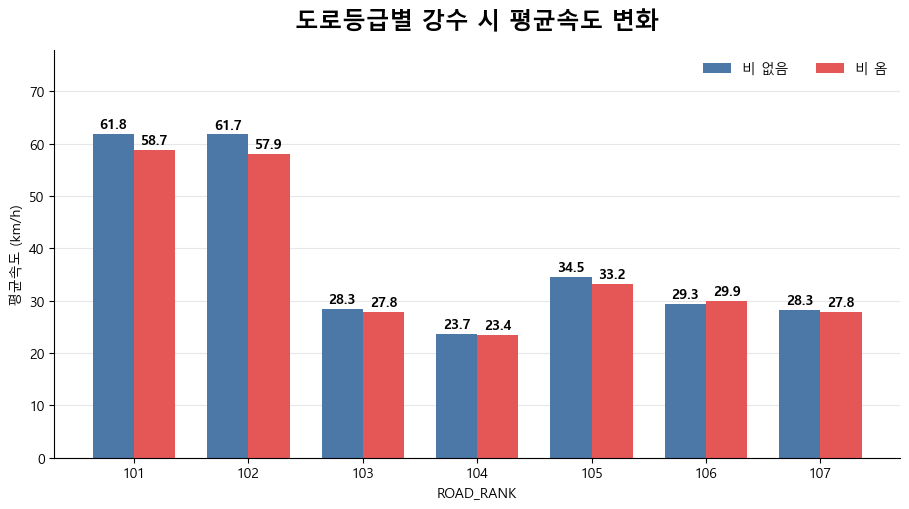

저장: C:\Users\ejjun\Desktop\seoul-eco-routing\docs\figures\eda\06_road_rank_rain_speed.png


In [15]:
pivot = speed_by_road_rank_rain.pivot(index="ROAD_RANK", columns="rain_flag", values="mean_speed").sort_index()
x = range(len(pivot))
width = 0.36

fig, ax = plt.subplots(figsize=(9.2, 5.2))
ax.bar([i - width / 2 for i in x], pivot["no_rain"], width, label="비 없음", color=COLORS["no_rain"])
ax.bar([i + width / 2 for i in x], pivot["rain"], width, label="비 옴", color=COLORS["rain"])
ax.set_xticks(list(x), [str(v) for v in pivot.index])
ax.set_title("도로등급별 강수 시 평균속도 변화", fontsize=17, fontweight="bold", pad=16)
ax.set_xlabel("ROAD_RANK")
ax.set_ylabel("평균속도 (km/h)")
ax.legend(frameon=False, ncols=2, loc="upper right")
add_labels(ax, dy=0.55)
finish(fig, ax, "06_road_rank_rain_speed.png", ylim_pad=0.2)

## 7. 보조 테이블 및 변수 상관관계

경사방향(오르막/내리막/평지)별, 도로등급×경사구간별 평균속도와, 평균속도와 다른 변수들의 상관관계를 확인합니다.

In [16]:
speed_by_slope_direction = summarize(df.groupby("slope_direction", observed=True))
speed_by_slope_direction

,slope_direction,row_count,mean_speed,median_speed,std_speed
0,downhill,585554,26.15,23.76,12.24
1,flat,1421634,25.66,23.17,12.36
2,uphill,612144,26.44,24.15,11.99


In [17]:
speed_by_road_rank_slope = summarize(df.groupby(["ROAD_RANK", "abs_slope_bin"], observed=True))
speed_by_road_rank_slope

,ROAD_RANK,abs_slope_bin,row_count,mean_speed,median_speed,std_speed
0,101,0-1%,4522,63.14,70.45,25.96
1,101,1-3%,4760,58.32,55.92,25.81
2,101,3-5%,238,57.11,52.33,21.83
3,101,5-10%,476,71.56,80.43,20.59
4,102,0-1%,61148,61.63,68.00,21.08
5,102,1-3%,22845,58.36,63.75,21.28
6,102,3-5%,7854,63.86,69.58,20.82
7,102,5-10%,6426,60.72,62.68,20.84
8,102,10%+,7854,60.49,65.08,22.00
9,103,0-1%,166112,27.38,26.05,10.16


In [18]:
corr_cols = ["평균속도", "precip_mm", "abs_slope_pct", "slope_pct", "elev_mean_m", "elev_delta_m", "MAX_SPD", "LENGTH"]
speed_feature_correlations = df[corr_cols].corr(numeric_only=True)["평균속도"].sort_values(ascending=False).reset_index()
speed_feature_correlations.columns = ["feature", "corr_with_avg_speed"]
speed_feature_correlations["corr_with_avg_speed"] = speed_feature_correlations["corr_with_avg_speed"].round(4)
speed_feature_correlations

,feature,corr_with_avg_speed
0,평균속도,1.0000
1,MAX_SPD,0.4967
2,LENGTH,0.4471
3,abs_slope_pct,0.0549
4,elev_mean_m,0.0312
5,slope_pct,0.0071
6,elev_delta_m,0.0040
7,precip_mm,-0.0273


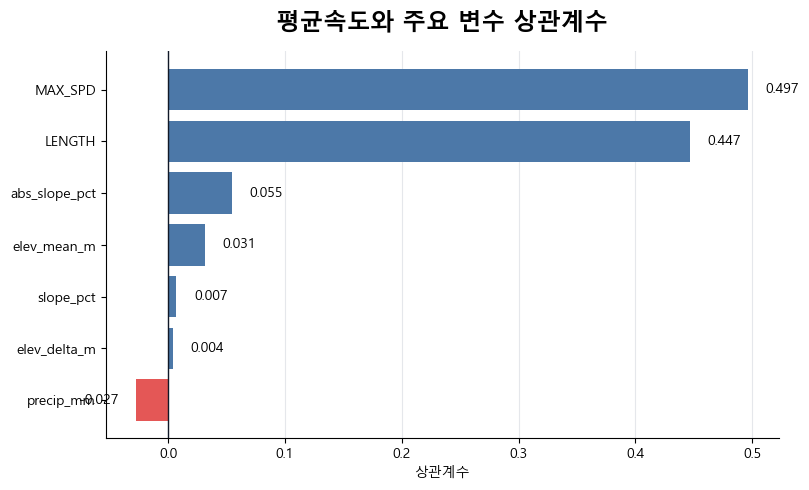

저장: C:\Users\ejjun\Desktop\seoul-eco-routing\docs\figures\eda\07_feature_correlation_speed.png


In [19]:
plot_df = speed_feature_correlations[speed_feature_correlations["feature"] != "평균속도"].copy()
plot_df = plot_df.sort_values("corr_with_avg_speed")
colors = ["#E45756" if v < 0 else "#4C78A8" for v in plot_df["corr_with_avg_speed"]]

fig, ax = plt.subplots(figsize=(8.2, 5.0))
ax.barh(plot_df["feature"], plot_df["corr_with_avg_speed"], color=colors)
ax.axvline(0, color="#111827", linewidth=1)
ax.set_title("평균속도와 주요 변수 상관계수", fontsize=17, fontweight="bold", pad=16)
ax.set_xlabel("상관계수")
for patch in ax.patches:
    width = patch.get_width()
    x = width + (0.015 if width >= 0 else -0.015)
    ha = "left" if width >= 0 else "right"
    ax.text(x, patch.get_y() + patch.get_height() / 2, f"{width:.3f}", va="center", ha=ha, fontsize=10)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", color="#E5E7EB", linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(DOCS_FIGURES_DIR / "07_feature_correlation_speed.png", dpi=220, bbox_inches="tight")
plt.show()
print("저장:", DOCS_FIGURES_DIR / "07_feature_correlation_speed.png")

## 요약

In [20]:
no_rain_speed = speed_by_rain_flag.set_index("rain_flag").loc["no_rain", "mean_speed"]
rain_speed = speed_by_rain_flag.set_index("rain_flag").loc["rain", "mean_speed"]
no_rain_flat = speed_by_rain_slope_group.set_index("rain_slope_group").loc["no_rain + not_steep", "mean_speed"]
rain_steep = speed_by_rain_slope_group.set_index("rain_slope_group").loc["rain + steep", "mean_speed"]
peak_pivot = speed_by_peak_rain.pivot(index=speed_by_peak_rain.columns[0], columns="rain_flag", values="mean_speed")
t1_no_rain = peak_pivot.loc["T1", "no_rain"]
t1_rain = peak_pivot.loc["T1", "rain"]

print(f"무강수 평균속도: {no_rain_speed:.2f} km/h")
print(f"강수 평균속도: {rain_speed:.2f} km/h")
print(f"무강수 + 완만 구간 평균속도: {no_rain_flat:.2f} km/h")
print(f"강수 + 급경사 구간 평균속도: {rain_steep:.2f} km/h")
print(f"오전첨두 무강수 평균속도: {t1_no_rain:.2f} km/h")
print(f"오전첨두 강수 평균속도: {t1_rain:.2f} km/h")

무강수 평균속도: 26.05 km/h
강수 평균속도: 25.59 km/h
무강수 + 완만 구간 평균속도: 25.88 km/h
강수 + 급경사 구간 평균속도: 26.88 km/h
오전첨두 무강수 평균속도: 25.34 km/h
오전첨두 강수 평균속도: 23.01 km/h


이 결과는 인과관계 검증이 아니라 탐색적 분석입니다. 강수·급경사 구간, 특히 오전 첨두시간대 강수 시 평균속도가 뚜렷이 낮아지는 경향이 있지만, 최종 해석에서는 시간대·도로등급·제한속도·링크별 특성을 함께 통제해야 합니다.